# Sentralitas Jaringan

Sekarang pertanyaannya beda: dari sekian banyak node di dalam struktur web, gimana caranya kita ngukur mana yang penting? Datanya tetap graph, jadi yang kita pakai tetap analisis graph. Bedanya, di sini kita udah bisa ngomongin hasil crawling, hubungan kalimat dengan kalimat, sampai hubungan web dengan web.

Kalau yang dianalisis web dengan web, hasilnya nanti ketemu web penting di dalam kumpulan web. Misal web informatika nge-link ke fakultas atau prodi lain, atau dibalik, prodi lain yang nge-link ke informatika. Pola link kayak gini yang jadi dasar waktu kita belajar jejaring web, dan dari situ jugak konsep PageRank lahir: nyari halaman mana yang layak ditaruh sebagai halaman utama.

#### Ukuran paling dasar: sentralitas derajat

Ukuran paling lokal itu sentralitas derajat (degree centrality), intinya yaa jumlah sisi yang nyambung ke simpul itu:

$$C_D(i) = k_i$$

Biar bisa dibandingin antar graph yang jumlah simpulnya beda, dibagi derajat maksimal yang mungkin, yaitu $N-1$:

$$C'_D(i) = \frac{k_i}{N-1}$$

Artinya proporsi dari semua simpul lain yang bertetangga langsung sama $i$. Ukuran ini cuma ngeliat jarak satu langkah, jadi belum bisa nangkep siapa yang jadi jembatan.

Seberapa merata sentralitas kebagi di seluruh graph diukur pakai sentralisasi (centralization). Rumus umum Freeman:

$$C_D = \frac{\sum_{i} \left[ C_D(n^*) - C_D(i) \right]}{(N-1)(N-2)}$$

$n^*$ itu simpul paling sentral, jadi pembilangnya jumlah selisih antara simpul paling sentral sama semua simpul lain. Penyebutnya selisih maksimum yang mungkin, yaitu bentuk graph bintang. Rentang nilainya $[0,1]$.

#### Betweenness centrality: simpul jembatan

Bayangin ada dua kelompok node yang sebenernya gak nyambung langsung. Kalau ada satu node yang jadi satu-satunya jalan buat nyambungin dua kelompok itu, node itulah jembatannya. Tujuannya jelas: nyari siapa yang jadi jembatan antar kelompok.

Gunanya kepake banget kalau kita mau segmentasi atau bikin ringkasan yang isinya dua topik. Satu dokumen bisa punya beberapa topik, tiap topik punya kata-kata yang nyambung ke topik itu. Kalau simpul jembatannya saya ambil, dokumennya pecah jadi dua topik. Kalau jembatannya gak diambil, dokumennya tetap satu topik.

Buat ngukur betweenness, kita harus paham dulu rumusnya. Idenya: berapa banyak pasangan node yang jalur terpendeknya harus lewat node kita.

$$C_B(i) = \sum_{j < k} \frac{g_{jk}(i)}{g_{jk}}$$

$g_{jk}$ itu jumlah jalur terpendek yang nyambungin $j$ dan $k$, sedangkan $g_{jk}(i)$ itu jumlah jalur terpendek tadi yang lewat $i$. Jadi kalau dari semua jalur terpendek antara $j$ dan $k$ cuma sebagian yang lewat $i$, nilainya dibagi sesuai porsi.

Biasanya dinormalisasi biar rentangnya rapi. Buat graph tidak berarah, jumlah pasangannya $\frac{(N-1)(N-2)}{2}$:

$$C'_B(i) = \frac{C_B(i)}{(N-1)(N-2)/2}$$

Buat graph berarah, jalurnya gak simetris, jadi pembaginya $(N-1)(N-2)$. Ini yang dipakai networkx waktu `normalized=True`.

Contoh kecil dari dosen, jaringan garis A-B-C-D-E. Nilainya A 0, B 3, C 4, D 3, E 0. B ada di antara A dan tiga simpul lain, yaitu C, D, dan E. C ada di antara empat pasang simpul, yaitu (A,D), (A,E), (B,D), dan (B,E). Karna gak ada jalur alternatif buat pasangan-pasangan itu, C dapat nilai penuh.

Kalau jalurnya bercabang, nilainya dibagi. Di contoh kedua, C dan D masing-masing dapat 1, karna dua-duanya sama-sama ada di jalur terpendek buat pasangan (A,E) dan (B,E), jadi harus berbagi setengah-setengah.

#### Closeness centrality

Closeness itu banyaknya jarak dari tiap pasangan node, dengan catatan pasangan node-nya gak boleh node yang sama. Simpelnya: seberapa deket node ini ke semua node lain.

$$C_C(i) = \left[ \sum_{j=1}^{N} d(i,j) \right]^{-1}$$

Kalau jarak totalnya kecil, closeness-nya besar, artinya dia cepet dijangkau atau cepet nyebarin informasi ke seluruh jaringan.

Versi ternormalisasinya dikali $N-1$, biar bisa dibandingin antar graph:

$$C'_C(i) = C_C(i) \cdot (N-1)$$

Contoh dari dosen, simpul A jaraknya 1, 2, 3, dan 4 dari simpul lain. Jumlahnya 10, jadi $C_C(A) = \frac{1}{10} = 0{,}1$, terus versi ternormalisasinya $0{,}1 \times 4 = 0{,}4$.

#### Dari sentralitas ke prestise

Kalau sentralitas gak peduli arah sisi, prestise peduli. Prestise itu ukuran prominensi yang ngitung busur, jadi simpul yang banyak jadi sasaran panah dianggap berprestise. Contohnya suara di pemilu, hyperlink di web, like di TikTok, dan sitasi makalah.

Versi paling sederhana prestise itu in-degree, $P_D(i) = k_i^{in}$, dan versi ternormalisasinya $\frac{k_i^{in}}{N-1}$. Tapi ini cuma ngitung tetangga langsung.

Versi yang lebih pintar itu rank prestise: prestise kamu ikut naik kalau yang milih kamu jugak berprestise.

$$PR(i) = \sum_{j \in In(i)} PR(j)$$

#### PageRank

PageRank itu variasi rank prestise, bedanya prestise pemilih dibagi rata ke semua target tautannya:

$$PR(i) = \sum_{j \in In(i)} \frac{PR(j)}{k_j^{out}}$$

Biar gak ada simpul yang mati gara-gara gak punya tetangga masuk, ditambah faktor damping $\alpha$ dan lompatan acak:

$$PR(i) = \frac{1-\alpha}{N} + \alpha \sum_{j \in In(i)} \frac{PR(j)}{k_j^{out}}$$

Nilai $\alpha$ biasanya 0,85. Kelebihan PageRank di konteks pencarian: susah dimanipulasi pakai tautan spam, dan skornya gak bergantung sama kueri yang diketik.

Bentuk matriksnya begini. Matriks adjacency $A$ isinya 1 kalau ada busur dari $i$ ke $j$, terus matriks transisi $M$ tiap barisnya dibagi out-degree:

$$M_{ij} = \frac{A_{ij}}{k_i^{out}}$$

Matriks Google-nya:

$$G = \alpha M + \frac{1-\alpha}{N} J$$

dengan $J$ matriks berisi 1 semua. Vektor PageRank $r$ itu eigenvector kiri dari $G$, jadi dicari iteratif pakai

$$r = G^{\top} r$$

diulang sampai nilainya konvergen. Total semua skornya selalu 1.

#### Catatan tugas dan rencana project

Tugas yang ada di catatan saya: bikin graph berarah 4 node pakai networkx, hitung PageRank tiap node, terus bentuk representasi matriksnya. Itu udah dikerjain di bawah, lengkap dengan matriks adjacency, matriks transisi, matriks Google, dan power iteration-nya.

Rencana project-nya: bikin hubungan website dengan website. Mulai dari website trunojoyo, ambil link keluar, terus link yang dituju diekstrak lagi, diulang terus sampai kebentuk hubungan antar website. Setelah itu hasilnya dideploy di server lab.

Project 1: crawling website trunojoyo, ekstrak website, bentuk graph buat dianalisis, cari website mana yang penting, hitung PageRank tiap page, terus ambil ranking 10 tertinggi dari sekitar 100 ribu node.

Penjelasan Project 1 : Sistem akan melakukan proses web crawling dengan mengekstraksi URL atau tautan dari sebuah website. Setiap tautan yang ditemukan akan dikunjungi dan diekstraksi kembali secara berulang hingga terbentuk hubungan antarwebsite.
Hasil crawling kemudian divisualisasikan dalam bentuk graph yang menunjukkan keterhubungan antarwebsite. Selanjutnya, sistem akan menerapkan algoritma PageRank untuk menghitung tingkat kepentingan atau pengaruh setiap website berdasarkan hubungan tautan yang ditemukan.
Dengan demikian, sistem dapat menentukan website mana yang memiliki tingkat kepentingan paling tinggi berdasarkan hasil crawling dan perhitungan PageRank.


## Tugas: PageRank Graph Berarah 4 Node

Graph terdiri dari 4 halaman (A, B, C, D). Panah menunjukkan arah link antar halaman. 
Nilai PageRank dihitung dengan `nx.pagerank()` menggunakan faktor damping standar alpha = 0.85, 
lalu diperiksa ulang melalui representasi matriks (adjacency, transisi, dan matriks Google).

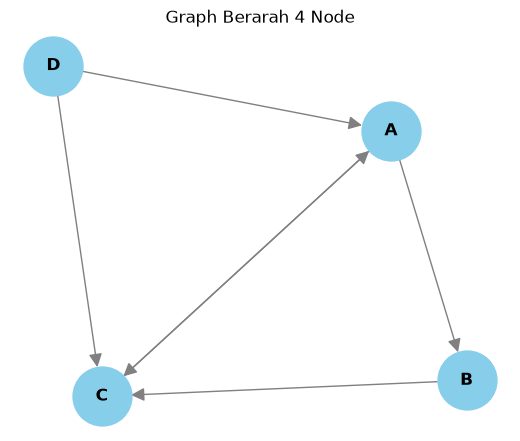

Nilai PageRank tiap node:
  C: 0.3839
  A: 0.3797
  B: 0.1989
  D: 0.0375

Total PageRank: 1.0000


In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Buat graph berarah dengan 4 node
G = nx.DiGraph()

G.add_nodes_from(["A", "B", "C", "D"])
G.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "C"),
    ("C", "A"),
    ("D", "A"),
    ("D", "C"),
])

# 2. Gambarkan graph berarahnya
pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(5, 4))
nx.draw(
    G, pos,
    with_labels=True,
    node_color="skyblue",
    node_size=1800,
    arrowsize=20,
    font_size=12,
    font_weight="bold",
    edge_color="gray",
)
plt.title("Graph Berarah 4 Node")
plt.show()

# 3. Hitung PageRank tiap node
pagerank = nx.pagerank(G, alpha=0.85)

print("Nilai PageRank tiap node:")
for node, score in sorted(pagerank.items(), key=lambda item: item[1], reverse=True):
    print(f"  {node}: {score:.4f}")

print(f"\nTotal PageRank: {sum(pagerank.values()):.4f}")

### Representasi Matriks

PageRank dapat dihitung lewat matriks:

- **A** = matriks adjacency, `A[i][j] = 1` jika ada edge dari node i ke node j.
- **M** = matriks transisi, yaitu A yang setiap barisnya dibagi dengan out-degree node tersebut (jumlah tiap baris = 1).
- **G** = matriks Google, `G = alpha * M + (1 - alpha) / n * J`, dengan J matriks berisi 1 semua.

Vektor PageRank **r** adalah eigenvector kiri dari G, sehingga dicari secara iteratif dengan **r** = Gᵀ**r** (power iteration).

In [2]:
import numpy as np
import pandas as pd

nodes = list(G.nodes())
n = len(nodes)
alpha = 0.85

# Matriks adjacency A: A[i][j] = 1 jika ada edge i -> j
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
print("Matriks adjacency (A):")
display(pd.DataFrame(A.astype(int), index=nodes, columns=nodes))

# Matriks transisi M: setiap baris dibagi out-degree
out_degree = A.sum(axis=1, keepdims=True)
out_degree[out_degree == 0] = 1  # hindari pembagian nol pada dangling node
M = A / out_degree
print("\nMatriks transisi (M), jumlah tiap baris = 1:")
display(pd.DataFrame(M.round(3), index=nodes, columns=nodes))

# Matriks Google: G = alpha * M + (1 - alpha) / n * J
J = np.ones((n, n))
M_google = alpha * M + (1 - alpha) / n * J
print("\nMatriks Google (alpha = 0.85):")
display(pd.DataFrame(M_google.round(4), index=nodes, columns=nodes))

# Power iteration: r = G^T r
r = np.ones(n) / n
for _ in range(100):
    r_new = M_google.T @ r
    if np.allclose(r, r_new, atol=1e-12):
        r = r_new
        break
    r = r_new

print("\nPageRank hasil perkalian matriks:")
for node, score in sorted(zip(nodes, r), key=lambda item: -item[1]):
    print(f"  {node}: {score:.4f}")

Matriks adjacency (A):


,A,B,C,D
A,0,1,1,0
B,0,0,1,0
C,1,0,0,0
D,1,0,1,0



Matriks transisi (M), jumlah tiap baris = 1:


,A,B,C,D
A,0.0,0.5,0.5,0.0
B,0.0,0.0,1.0,0.0
C,1.0,0.0,0.0,0.0
D,0.5,0.0,0.5,0.0



Matriks Google (alpha = 0.85):


,A,B,C,D
A,0.0375,0.4625,0.4625,0.0375
B,0.0375,0.0375,0.8875,0.0375
C,0.8875,0.0375,0.0375,0.0375
D,0.4625,0.0375,0.4625,0.0375



PageRank hasil perkalian matriks:
  C: 0.3839
  A: 0.3797
  B: 0.1989
  D: 0.0375


### Interpretasi

- **C** memiliki PageRank tertinggi karena menerima link dari A, B, dan D.
- **A** hampir setara karena menerima link dari C dan D, lalu meneruskan link ke B dan C.
- **B** hanya menerima link dari A.
- **D** paling kecil karena hanya mengirim link dan tidak menerima link dari node lain.

## Project 1: Crawler + PageRank Website Trunojoyo

Project 1 yang ada di catatan atas akhirnya jadi aplikasi. Aplikasinya kubikin pakai Streamlit, foldernya `aplikasi-crawler-pagerank`, struktur foldernya ngikutin `aplikasi-klasifikasi-berita` biar konsisten.

Alurnya gini: mulai dari satu URL, crawler ngambil halaman pakai BFS, semua tautan di halaman diekstrak, tautan yang masih satu domain masuk antrean, terus diulang sampai batas halaman atau kedalaman kekabul. Tiap pasangan halaman asal dan tujuan dicatat sebagai busur, jadi begitu crawl selesai kita udah punya graph berarah. Graph itu yang dihitung PageRank-nya pakai alpha 0.85, terus hasilnya diurutin dari skor paling besar. Di aplikasinya semua halaman kutampilin, bukan cuma 10 teratas, jadi jumlah barisnya ngikut batas halaman yang di-crawl.

Isi foldernya: `app/crawler.py` buat crawling dan ekstraksi tautan, `app/graph_analysis.py` buat bangun graph, PageRank, statistik, dan gambar graph, `app/graph_interaktif.py` buat graph interaktifnya, `app/streamlit_app.py` antarmuka Streamlit-nya, terus `run_crawl.py` versi terminal buat crawl besar, misal sampai 100 ribu node.

Graph di aplikasi sengaja kubikin interaktif, bukan gambar diam. Jadi bisa di-scroll buat zoom, ditarik buat geser, simpulnya bisa digeser, dan kalau di-hover keluar judul halaman, URL, skor PageRank, plus in/out-degree-nya. Posisi simpul dihitung dulu pakai spring layout biar pas dibuka langsung rapi, dan ada opsi animasi fisika kalau mau simpulnya saling tarik-menarik. HTML graph-nya juga bisa diunduh, file-nya mandiri jadi bisa dibuka di browser mana aja tanpa internet.

Cara jalanin aplikasinya, dari folder `aplikasi-crawler-pagerank`: `..\enwebmining\Scripts\python.exe -m streamlit run app\streamlit_app.py`.

Satu hal yang belajar dari ngerjain ini: menu header dan footer itu muncul di semua halaman, jadi kalau semua tautan dihitung, semua halaman saling nyambung ke halaman menu yang sama. Efeknya graph jadi hampir lengkap dan PageRank halaman-halaman menu seri semua, contohnya waktu 25 halaman pertama semuanya dapat 0.064. Makanya di aplikasi ada opsi abaikan menu navigasi, dan di bawah ini kupakai opsi itu biar hubungan antarwebsite lebih mencerminkan isi halaman.


In [3]:
import sys
from pathlib import Path

import pandas as pd

# notebook ini bisa dibuka dari folder Notebooks atau dari akar Webmining
akar = Path.cwd()
if not (akar / "aplikasi-crawler-pagerank").exists():
    akar = akar.parent
sys.path.insert(0, str(akar / "aplikasi-crawler-pagerank"))

from app.crawler import crawl
from app.graph_analysis import bangun_graph, peringkat_pagerank, statistik_graph

hasil = crawl(
    "https://trunojoyo.ac.id",
    max_pages=25,
    max_depth=3,
    delay=0.1,
    abaikan_navigasi=True,
)

G_web = bangun_graph(hasil)
tabel_web = peringkat_pagerank(G_web, alpha=0.85)
stat_web = statistik_graph(G_web)

print(f"Halaman berhasil diambil : {stat_web['simpul']}")
print(f"Busur (tautan)           : {stat_web['busur']}")
print(f"Density graph            : {stat_web['density']:.4f}")
print(f"Rata-rata out-degree     : {stat_web['rata2_out']:.2f}")
print(f"Waktu crawl              : {hasil.duration:.1f} detik")
print(f"Gagal diambil            : {len(hasil.errors)} halaman")
print()
print(f"{len(tabel_web)} halaman, urut dari PageRank tertinggi:")
print(tabel_web[
    ["peringkat", "pagerank", "in_degree", "out_degree", "url"]
].to_string(index=False))


Halaman berhasil diambil : 25
Busur (tautan)           : 223
Density graph            : 0.3717
Rata-rata out-degree     : 8.92
Waktu crawl              : 8.5 detik
Gagal diambil            : 1 halaman

25 halaman, urut dari PageRank tertinggi:
 peringkat  pagerank  in_degree  out_degree                                                                                                                                                                  url
         1  0.164752         24           4                                                                                                                                        https://www2.trunojoyo.ac.id/
         2  0.107980         24           1                                                                                                                          https://www2.trunojoyo.ac.id/cookie-policy/
         3  0.103964         23          22                                                                                      

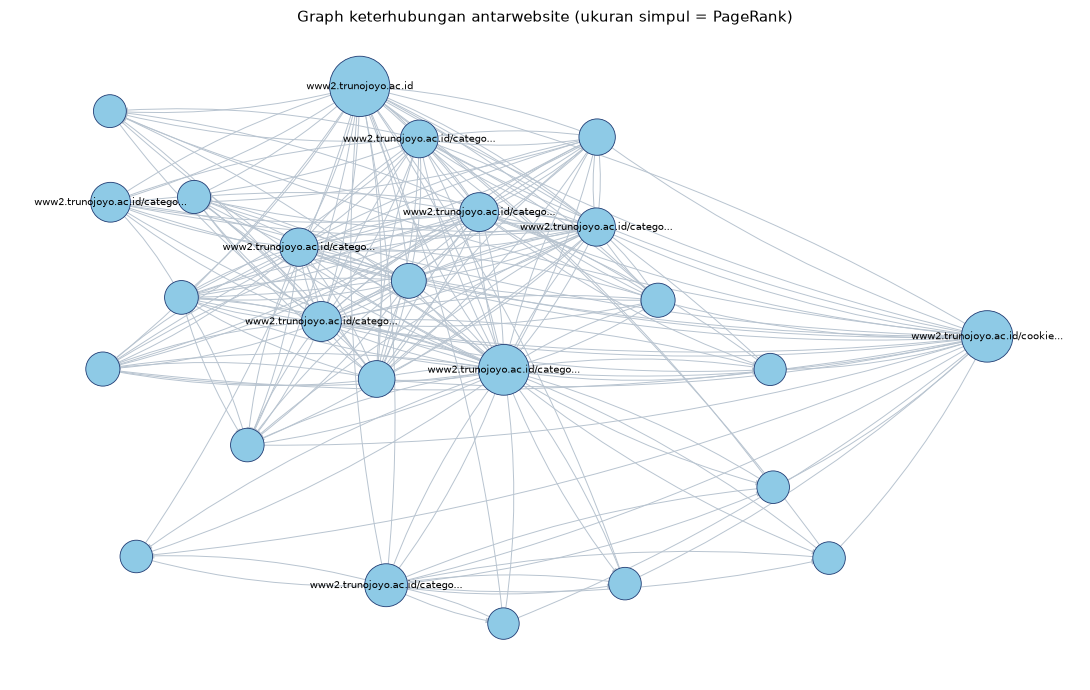

In [4]:
import matplotlib.pyplot as plt

from app.graph_analysis import gambar_graph

fig = gambar_graph(G_web, tabel_web, maks_label=10)
plt.show()


### Bukti sekaligus penjelasan hasilnya

Dari 25 halaman yang berhasil diambil, kebentuk 223 busur dengan density 0.3717 dan waktu crawl 8.5 detik. Artinya rata-rata satu halaman punya 8.92 tautan keluar ke halaman lain di domain yang sama. Tabel di atas sengaja kucetak seluruhnya, bukan cuma 10 teratas, biar keliatan kalau ekor ranking-nya diisi artikel berita dan pengumuman yang cuma di-link dari beberapa halaman.

Peringkat teratas diisi homepage `www2.trunojoyo.ac.id` dengan skor 0.164752, terus ada `cookie-policy` di posisi kedua dengan 0.107980. Homepage menang karena paling banyak di-link balik dari halaman lain, dan dia juga ngirim tautan ke banyak halaman sekaligus, jadi di mata PageRank dia penting. `category/headlines/` yang skornya 0.103964 juga masuk akal: dia halaman kumpulan berita yang jadi pintu masuk banyak artikel.

Density 0.3717 itu termasuk padat buat 25 halaman, wajar karna halaman kategori masih saling nyambung lewat daftar berita dan tautan lanjutan.

Yang menarik, skor tertinggi gak selalu halaman yang isinya paling penting. Di sini `cookie-policy` dapat in-degree 24, sama kayak homepage, gara-gara tautannya nempel di banner cookie yang muncul di hampir semua halaman. Ini contoh bagus kalau struktur tautan bisa "ditipu" elemen yang muncul di mana-mana, dan itu jugak alasan skor PageRank gak bisa dibaca mentah-mentah tanpa lihat konteks tautannya.

Grafiknya keliatan seperti bintang: satu simpul besar di tengah terus banyak simpul kecil di pinggir. Ukuran simpul ngikutin skor PageRank, dan label cuma dipasang di 10 halaman teratas biar gak numpuk. Buat 25 halaman tampilannya masih kebaca, tapi kalau node-nya udah ratusan ribu, gambarnya mending dibuka di Gephi pakai file GraphML.

Buat skala 100 ribu node, aplikasi web sengaja kubatasi 300 halaman biar browser gak nunggu kelamaan. Versi besarnya lewat `run_crawl.py --max-pages 100000`, hasilnya disimpan sebagai `pagerank_<waktu>.csv`, `busur_<waktu>.csv`, dan `graph_<waktu>.graphml`. Contoh hasil crawl 100 halaman udah ada di folder `output/`, isinya 907 busur dengan density 0.0916.
